## TF-IDF baseline for ternary AI-text detection

In [ ]:
>This version uses the untruncated data in `english_slice`, which contains full wiki+academic froms `trinary_open.json` in DetectRL-X dataset.

In [1]:
!pip -q install huggingface_hub ijson scikit-learn pandas matplotlib
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, accuracy_score)

In [2]:
# connect to a runtime and upload english_slice.csv
!pwd
!ls

/content
english_slice.csv  sample_data


In [3]:
# load dataset

df = pd.read_csv("/content/english_slice.csv")
display(df.head())

,text,label,pair_id,lang,model,domain,split
0,Attention to the buffer zone as one such site ...,human,110250,english,deepseek-v3,Academic,test
1,The notion of the buffer zone represents a cri...,ai_generated,110250,english,deepseek-v3,Academic,test
2,Examining the buffer zone reveals how such sit...,ai_refined,110250,english,deepseek-v3,Academic,test
3,The North was fighting for a just cause – the ...,human,110251,english,deepseek-v3,Academic,test
4,Cosmopolitan Liberalism and the Moral Limits o...,ai_generated,110251,english,deepseek-v3,Academic,test


In [4]:
# preliminary analysis

print("class distribution:")
print(df["label"].value_counts())
print("\ntrain/test split distribution:")
print(df["split"].value_counts())

class distribution:
label
human           5200
ai_generated    5200
ai_refined      5200
Name: count, dtype: int64

train/test split distribution:
split
train    9600
test     6000
Name: count, dtype: int64


In [5]:
# test splits

train_raw = df[df["split"] == "train"].copy()
test = df[df["split"] == "test"].copy()

split = GroupShuffleSplit()

train_idx, val_idx = next(split.split(train_raw, groups=train_raw["pair_id"]))
train = train_raw.iloc[train_idx].copy()
validation = train_raw.iloc[val_idx].copy()

print("split sizes:")
print("training:", len(train))
print("validation:", len(validation))
print("testing:", len(test))

split sizes:
training: 7680
validation: 1920
testing: 6000


In [6]:
# train baseline model (tf-idf + log regression)

baseline = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", LogisticRegression())
])

baseline.fit(train["text"], train["label"])

Pipeline(steps=[('tfidf', TfidfVectorizer()),
                ('classifier', LogisticRegression())])

Test accuracy: 0.8657
Test macro-F1: 0.8637

Classification report:
              precision    recall  f1-score   support

       human     0.8263    0.8965    0.8600      2000
ai_generated     0.9144    0.9555    0.9345      2000
  ai_refined     0.8563    0.7450    0.7968      2000

    accuracy                         0.8657      6000
   macro avg     0.8656    0.8657    0.8637      6000
weighted avg     0.8656    0.8657    0.8637      6000



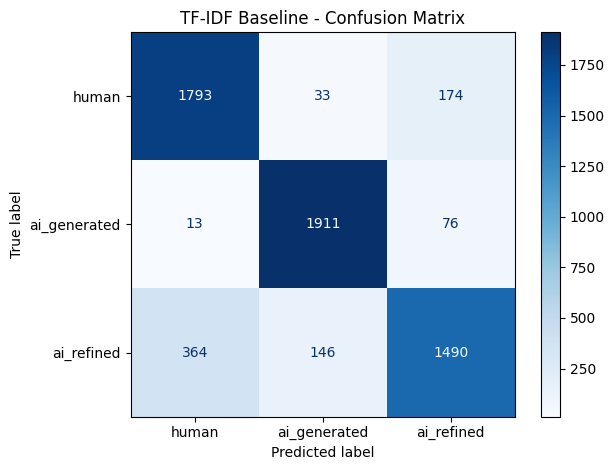


Correct predictions:


,label,prediction,domain,model,pair_id,text
0,human,human,Academic,deepseek-v3,110250,Attention to the buffer zone as one such site ...
1,ai_generated,ai_generated,Academic,deepseek-v3,110250,The notion of the buffer zone represents a cri...
2,ai_refined,ai_refined,Academic,deepseek-v3,110250,Examining the buffer zone reveals how such sit...
3,human,human,Academic,deepseek-v3,110251,The North was fighting for a just cause – the ...
4,ai_generated,ai_generated,Academic,deepseek-v3,110251,Cosmopolitan Liberalism and the Moral Limits o...



Incorrect predictions:


,label,prediction,domain,model,pair_id,text
9,human,ai_refined,Academic,deepseek-v3,110253,Now ask: is this putatively democratic society...
18,human,ai_refined,Academic,deepseek-v3,110256,Recent research indicates that processing grey...
24,human,ai_refined,Academic,deepseek-v3,110258,"At the same time, adjustments are made to alig..."
33,human,ai_refined,Academic,deepseek-v3,110261,We excluded one male with IR>ER because of ext...
34,ai_generated,ai_refined,Academic,deepseek-v3,110261,The Influence of Hip Kinematics on Knee Loadin...
38,ai_refined,ai_generated,Academic,deepseek-v3,110262,Through analyzing the disease's transmission p...
53,ai_refined,ai_generated,Academic,deepseek-v3,110267,A more developed policy framework would incorp...
65,ai_refined,ai_generated,Academic,deepseek-v3,110271,"From Jaworski and Thurlow’s perspective, they ..."
70,ai_generated,ai_refined,Academic,deepseek-v3,110273,Performance Evaluation of RSA Algorithm Varian...
93,human,ai_generated,Academic,deepseek-v3,110282,"This means acknowledging who customers are, wh..."



Error counts by true and predicted labels:


prediction,ai_generated,ai_refined,human
label,,,
ai_generated,1911,76,13
ai_refined,146,1490,364
human,33,174,1793



Accuracy by domain:


,count,mean
domain,,
Academic,3000,0.875667
Wiki,3000,0.855667



Accuracy by model:


,count,mean
model,,
deepseek-v3,1500,0.914000
gemini-2.5-flash,1500,0.866667
gpt-4o,1500,0.860000
qwen-max,1500,0.822000


In [7]:
# evaluation

from sklearn.metrics import (
    classification_report,
    accuracy_score,
    f1_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# 1. Quantitative evaluation
y_pred = baseline.predict(test["text"])
y_true = test["label"]

print("Test accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Test macro-F1:", round(f1_score(y_true, y_pred, average="macro"), 4))

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=["human", "ai_generated", "ai_refined"],
    digits=4,
    zero_division=0
))

# 2. Confusion matrix
labels = ["human", "ai_generated", "ai_refined"]

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=labels,
    display_labels=labels,
    cmap="Blues",
    values_format="d"
)

plt.title("TF-IDF Baseline - Confusion Matrix")
plt.tight_layout()
plt.show()

# 3. Qualitative error analysis
results = test.copy()
results["prediction"] = y_pred
results["correct"] = results["label"] == results["prediction"]

print("\nCorrect predictions:")
display(results[results["correct"]][
    ["label", "prediction", "domain", "model", "pair_id", "text"]
].head(5))

print("\nIncorrect predictions:")
display(results[~results["correct"]][
    ["label", "prediction", "domain", "model", "pair_id", "text"]
].head(10))

# 4. Error distribution
print("\nError counts by true and predicted labels:")
display(pd.crosstab(results["label"], results["prediction"]))

print("\nAccuracy by domain:")
display(results.groupby("domain")["correct"].agg(["count", "mean"]))

print("\nAccuracy by model:")
display(results.groupby("model")["correct"].agg(["count", "mean"]))